# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'saumyap2'   # <-- set this
d = np.genfromtxt(f'../../labs/07/data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

273 epochs over 958 days; median quoted error 0.040 mag; rms of the light curve 0.320 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


Highest peak period: 299.67 days
Peak power: 0.4126
False-alarm probability: 3.3158e-29


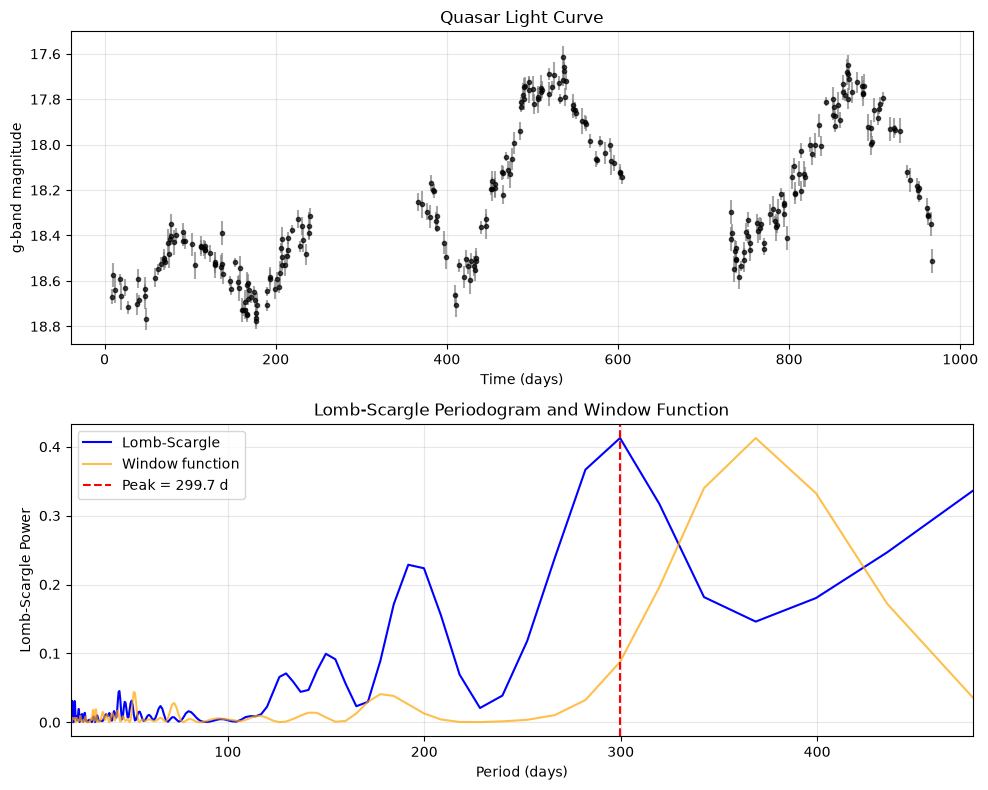

In [30]:
# Part 1: your work here

f_min = 2 / T
f_max = 1 / 20
df = 1 / (5 * T)

freq = np.linspace(f_min, f_max, int(np.ceil((f_max - f_min) / df)) + 1)
periods = 1 / freq

# Lomb-Scargle periodogram
ls = LombScargle(t, y, dy=e)
power = ls.power(freq)

# Window function
window_ls = LombScargle(t, np.ones_like(y),
                        fit_mean=False, center_data=False)
window_power = window_ls.power(freq)
window_scaled = window_power / window_power.max() * power.max()

# Highest peak and false alarm probability
peak_idx = np.argmax(power)
best_period = periods[peak_idx]
peak_power = power[peak_idx]

fap = ls.false_alarm_probability(
    peak_power, method='baluev',
    minimum_frequency=f_min, maximum_frequency=f_max
)

print(f"Highest peak period: {best_period:.2f} days")
print(f"Peak power: {peak_power:.4f}")
print(f"False-alarm probability: {fap:.4e}")

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

ax[0].errorbar(t, y, yerr=e, fmt='.', color='black',
               ecolor='gray', alpha=0.7, capsize=0)
ax[0].invert_yaxis()
ax[0].set_xlabel('Time (days)')
ax[0].set_ylabel('g-band magnitude')
ax[0].set_title('Quasar Light Curve')
ax[0].grid(alpha=0.3)

ax[1].plot(periods, power, label='Lomb-Scargle', color='blue')
ax[1].plot(periods, window_scaled, label='Window function',
           color='orange', alpha=0.7)
ax[1].axvline(best_period, color='red', linestyle='--',
              label=f'Peak = {best_period:.1f} d')

ax[1].set_xlabel('Period (days)')
ax[1].set_ylabel('Lomb-Scargle Power')
ax[1].set_title('Lomb-Scargle Periodogram and Window Function')
ax[1].set_xlim(20, T / 2)
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**ANSWER (a few sentences):**

A period of 299.67 days is the highest peak. Secondary peaks at ~150 and ~190 days could be aliases. The window function peaks near 370 days due to observing gaps, but the LombScargle periodogram does not show a peak there. We don't search beyond $T/2$ because then fewer than 2 full cycles would have been observed and the period would be hard to confirm and defend. Astropy's fals alarm probability assumes uncorrelated Gaussion noise, or white noise, so it overestimates confidence in the peak when the quasar's variability follows DRW, explaining the small value.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


In [31]:
# Part 2: your work here

dt = np.abs(t[:, None] - t[None, :])

def log_likelihood(theta):
    mu, ln_sigma, ln_tau = theta
    sigma, tau = np.exp(ln_sigma), np.exp(ln_tau)

    C = sigma**2 * np.exp(-dt / tau)
    C[np.diag_indices_from(C)] += e**2

    r = y - mu

    try:
        cf = cho_factor(C, lower=True, check_finite=False)
        alpha = cho_solve(cf, r, check_finite=False)

        logdet = 2 * np.sum(np.log(np.diag(cf[0])))

        return -0.5 * (r @ alpha + logdet + len(y) * np.log(2 * np.pi))
    except np.linalg.LinAlgError:
        return -np.inf


def log_prior(theta):
    mu, ln_sigma, ln_tau = theta

    if (np.log(0.01) < ln_sigma < np.log(3) and
        np.log(10) < ln_tau < np.log(4000)):
        return 0.0

    return -np.inf


def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


The DRW log-likelihood is

$$\ln L = -\frac{1}{2}(y-\mu)^T C^{-1}(y-\mu) + \ln|C| + N\ln(2\pi)]$$

where

$$C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\delta_{ij}.$$

The log-prior is

$$
\ln p(\theta) =
\begin{cases}
0, & 0.01 < \sigma < 3,\quad 10 < \tau < 4000\\
-\infty, & \text{otherwise}
\end{cases}
$$

where $\theta = (\mu,\ln\sigma,\ln\tau)$ and we assume a flat prior on $\mu$.

The log-posterior is

$$
\ln p(\theta|y) = \ln L + \ln p(\theta) + \text{constant}.
$$


Priors:

$\sigma$: (0.01,3). Units of mag. This allows a broad range of variability amplitudes without favoring a particular magnitude scale.

$\tau$: (10,4000), Units of days. This allows damping times from short-term variability to long-term scales longer than the observation baseline.

Since the observation ranged 958 days, damping times longer than this are hard to constrain. The 4000 day bound on $/tau$ prevents the posterior forever towards longer timescales, but it may shorten the upper tail and our uncertainty could be influenced by our prior.

Start 1: lnL = 348.179, tau = 160.9 d, success = True
Start 2: lnL = 348.179, tau = 160.9 d, success = True
Start 3: lnL = 348.179, tau = 160.9 d, success = True
Start 4: lnL = 348.179, tau = 160.9 d, success = True
Start 5: lnL = 348.179, tau = 160.9 d, success = True

Maximum likelihood:
mu = 18.3238 mag
sigma = 0.2807 mag
tau = 160.92 days


100%|██████████████████████████████████████| 4000/4000 [01:53<00:00, 35.39it/s]



Convergence diagnostics:
Mean acceptance fraction: 0.598
Integrated autocorrelation times: [46.  53.3 52.3]
Chain length / max autocorr time: 75.0
Autocorrelation convergence criterion satisfied.

Posterior estimates (median and 68% interval):
sigma = 0.5039 (+0.4588 / -0.1989) mag
tau = 529.84 (+1492.62 / -340.28) days
T/tau = 1.809
68% interval for T/tau: [0.474, 5.055]


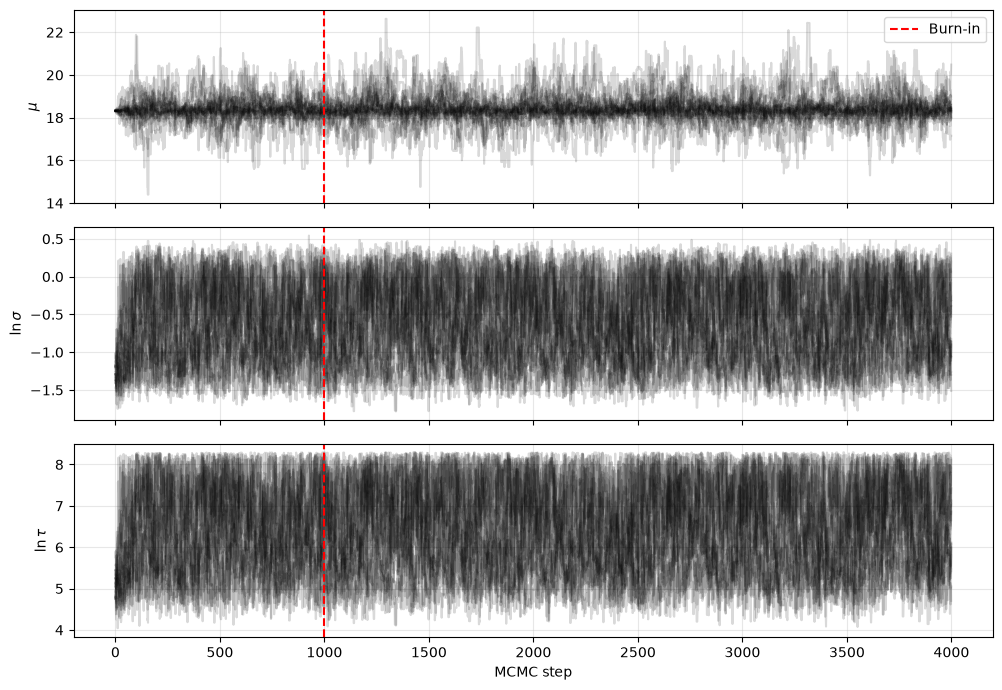

In [32]:
2.
# Starting points
bounds = [(None, None),
          (np.log(0.01), np.log(3)),
          (np.log(10), np.log(4000))]

starts = [
    [np.mean(y), np.log(0.1), np.log(20)],
    [np.mean(y), np.log(0.2), np.log(100)],
    [np.mean(y), np.log(0.3), np.log(300)],
    [np.mean(y), np.log(0.4), np.log(1000)],
    [np.mean(y), np.log(0.5), np.log(3500)]
]

results = [
    minimize(lambda th: -log_likelihood(th), x0,
             method='L-BFGS-B', bounds=bounds)
    for x0 in starts
]

for i, r in enumerate(results):
    print(f"Start {i+1}: lnL = {-r.fun:.3f}, "
          f"tau = {np.exp(r.x[2]):.1f} d, success = {r.success}")

best = min(results, key=lambda r: r.fun)
mle = best.x

print("\nMaximum likelihood:")
print(f"mu = {mle[0]:.4f} mag")
print(f"sigma = {np.exp(mle[1]):.4f} mag")
print(f"tau = {np.exp(mle[2]):.2f} days")

np.random.seed(42)
nwalkers, ndim, nsteps = 24, 3, 4000

pos = mle + np.random.normal(
    scale=[0.02, 0.1, 0.25], size=(nwalkers, ndim)
)

# initial walkers
pos[:, 1] = np.clip(pos[:, 1], bounds[1][0]+1e-5, bounds[1][1]-1e-5)
pos[:, 2] = np.clip(pos[:, 2], bounds[2][0]+1e-5, bounds[2][1]-1e-5)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
sampler.run_mcmc(pos, nsteps, progress=True)


tau_int = sampler.get_autocorr_time(tol=0)
max_autocorr = np.max(tau_int)
acceptance = np.mean(sampler.acceptance_fraction)

print("\nConvergence diagnostics:")
print(f"Mean acceptance fraction: {acceptance:.3f}")
print(f"Integrated autocorrelation times: {np.round(tau_int, 1)}")
print(f"Chain length / max autocorr time: {nsteps/max_autocorr:.1f}")

if nsteps > 50 * max_autocorr:
    print("Autocorrelation convergence criterion satisfied.")
else:
    print("Convergence not established: increase nsteps and rerun.")

burn = min(max(nsteps//4, int(5*max_autocorr)), nsteps//2)
thin = max(1, int(max_autocorr/2))

samples = sampler.get_chain(discard=burn, thin=thin, flat=True)

sigma_samples = np.exp(samples[:, 1])
tau_samples = np.exp(samples[:, 2])

s16, s50, s84 = np.percentile(sigma_samples, [16, 50, 84])
t16, t50, t84 = np.percentile(tau_samples, [16, 50, 84])

print("\nPosterior estimates (median and 68% interval):")
print(f"sigma = {s50:.4f} (+{s84-s50:.4f} / -{s50-s16:.4f}) mag")
print(f"tau = {t50:.2f} (+{t84-t50:.2f} / -{t50-t16:.2f}) days")
print(f"T/tau = {T/t50:.3f}")
print(f"68% interval for T/tau: [{T/t84:.3f}, {T/t16:.3f}]")

chain = sampler.get_chain()
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

labels = [r'$\mu$', r'$\ln \sigma$', r'$\ln \tau$']

for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], color='black', alpha=0.15)
    ax.axvline(burn, color='red', linestyle='--', label='Burn-in')
    ax.set_ylabel(labels[i])
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel('MCMC step')
plt.tight_layout()
plt.show()


The likelihood may have local maxima or broad degeneracies between $\sigma$ and $\tau$. Starting the optimizer from different values helps check that it consistently finds the same maximum rather than a solution dependent on the initial guess.

MCMC results: The posterior medians and 68% intervals are $\sigma=0.5039^{+0.4588}_{-0.1989}$ mag and $\tau=529.84^{+1492.62}_{-340.28}$ days, giving $T/\tau=1.809$.

Convergence: I checked the trace plots, mean acceptance fraction (0.598), and integrated autocorrelation times (46.0, 53.3, 52.3 steps). The chains appear well mixed, and the 4000-step chain length is about 75 times the largest autocorrelation time, exceeding the 50-times criterion.

Our light curve spans only $T=958$ days. If $\tau$ is comparable to or longer than this baseline, we cannot observe enough independent variability cycles or damping behavior to constrain it precisely. The observation gaps also limit the data available, producing a potentially broad and asymmetric posterior for $\tau$.

In [33]:
# 3.

def log_likelihood_se(theta):
    mu, ln_sigma, ln_ell = theta
    sigma, ell = np.exp(ln_sigma), np.exp(ln_ell)

    # Squared-exponential covariance and measurement noise
    C = sigma**2 * np.exp(-0.5 * (dt / ell)**2)
    C[np.diag_indices_from(C)] += e**2

    r = y - mu

    try:
        cf = cho_factor(C, lower=True, check_finite=False)
        alpha = cho_solve(cf, r, check_finite=False)
        logdet = 2 * np.sum(np.log(np.diag(cf[0])))

        return -0.5 * (r @ alpha + logdet + len(y) * np.log(2*np.pi))
    except np.linalg.LinAlgError:
        return -np.inf


results_se = [
    minimize(lambda th: -log_likelihood_se(th), x0,
             method='L-BFGS-B', bounds=bounds)
    for x0 in starts
]

best_se = min(results_se, key=lambda r: r.fun)

lnL_drw = -best.fun
lnL_se = -best_se.fun
delta_lnL = lnL_drw - lnL_se

print(f"DRW maximum lnL = {lnL_drw:.3f}")
print(f"SE maximum lnL  = {lnL_se:.3f}")
print(f"Difference (DRW - SE) = {delta_lnL:.3f}")

print(f"\nSE best-fit sigma = {np.exp(best_se.x[1]):.4f} mag")
print(f"SE best-fit ell = {np.exp(best_se.x[2]):.2f} days")

if delta_lnL > 0:
    print(f"\nDRW has higher maximum lnL by {delta_lnL:.3f}")
else:
    print(f"\nSE has higher maximum lnL by {-delta_lnL:.3f}")


DRW maximum lnL = 348.179
SE maximum lnL  = 284.999
Difference (DRW - SE) = 63.180

SE best-fit sigma = 0.2448 mag
SE best-fit ell = 10.00 days

DRW has higher maximum lnL by 63.180


The DRW model has a higher maximum log-likelihood than the squared-exponential model, a difference of $\Delta\ln L=63.180$. This strongly favors the DRW model, suggesting that the quasar's brightness varies more irregularly on short timescales than the very smooth variations assumed by the squared-exponential kernel.

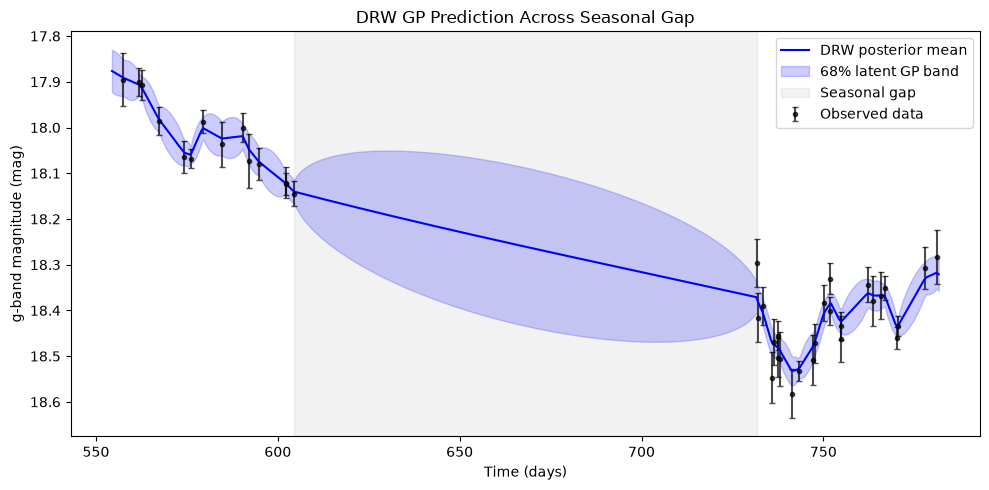

Seasonal gap: 604.4 to 731.7 days
Gap duration: 127.3 days


In [34]:
#4.
from scipy.linalg import cho_factor, cho_solve

# Best fit DRW parameters 
mu_gp = mle[0]
sigma_gp = np.exp(mle[1])
tau_gp = np.exp(mle[2])

#Largest seasonal gap
t_sorted = np.sort(t)
i_gap = np.argmax(np.diff(t_sorted))

gap_start = t_sorted[i_gap]
gap_end = t_sorted[i_gap + 1]

t_grid = np.linspace(gap_start - 50, gap_end + 50, 400)

K = sigma_gp**2 * np.exp(-dt / tau_gp)
C = K + np.diag(e**2)

K_star = sigma_gp**2 * np.exp(
    -np.abs(t_grid[:, None] - t[None, :]) / tau_gp
)

cf = cho_factor(C, lower=True)
alpha = cho_solve(cf, y - mu_gp)

pred_mean = mu_gp + K_star @ alpha

V = cho_solve(cf, K_star.T)

pred_var = sigma_gp**2 - np.sum(K_star * V.T, axis=1)
pred_std = np.sqrt(np.maximum(pred_var, 0))

plt.figure(figsize=(10, 5))

mask = (t >= t_grid.min()) & (t <= t_grid.max())

plt.errorbar(t[mask], y[mask], yerr=e[mask],
             fmt='.', color='black', alpha=0.7,
             capsize=2, label='Observed data')

plt.plot(t_grid, pred_mean, color='blue',
         label='DRW posterior mean')

plt.fill_between(t_grid,
                 pred_mean - pred_std,
                 pred_mean + pred_std,
                 color='blue', alpha=0.2,
                 label='68% latent GP band')

plt.axvspan(gap_start, gap_end,
            color='gray', alpha=0.1,
            label='Seasonal gap')

plt.xlabel('Time (days)')
plt.ylabel('g-band magnitude (mag)')
plt.title('DRW GP Prediction Across Seasonal Gap')
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

print(f"Seasonal gap: {gap_start:.1f} to {gap_end:.1f} days")
print(f"Gap duration: {gap_end - gap_start:.1f} days")

I used the best fit DRW kernel to predict the light curve across the largest seasonal gap, from 604.4 to 731.7 days. The posterior mean predicts a gradual increase in magnitude, while the 68% uncertainty band widens toward the middle of the gap due to the lack of observations and narrows near measured data.

The band represents the latent GP uncertainty, conditional on the best-fit parameters, rather than uncertainty in a new measurement. It does not include additional measurement noise, so observed points may fall outside the band due to their measurement errors. A predictive band for new measurements would be wider because it would include the observational noise variance.


HOLDOUT BLOCKS
Block 1: 8.9–38.9 days, 7 points
Block 2: 421.5–451.5 days, 12 points
Block 3: 567.2–597.2 days, 8 points
Block 4: 787.3–817.3 days, 13 points

Training points = 233
Held-out points = 40

DRW KERNEL
Number held out = 40
Inside 68% band = 29/40
Coverage fraction = 0.725 (72.5%)
R² = 0.9117
Training maximum lnL = 298.145

SE KERNEL
Number held out = 40
Inside 68% band = 28/40
Coverage fraction = 0.700 (70.0%)
R² = 0.7222
Training maximum lnL = 247.762


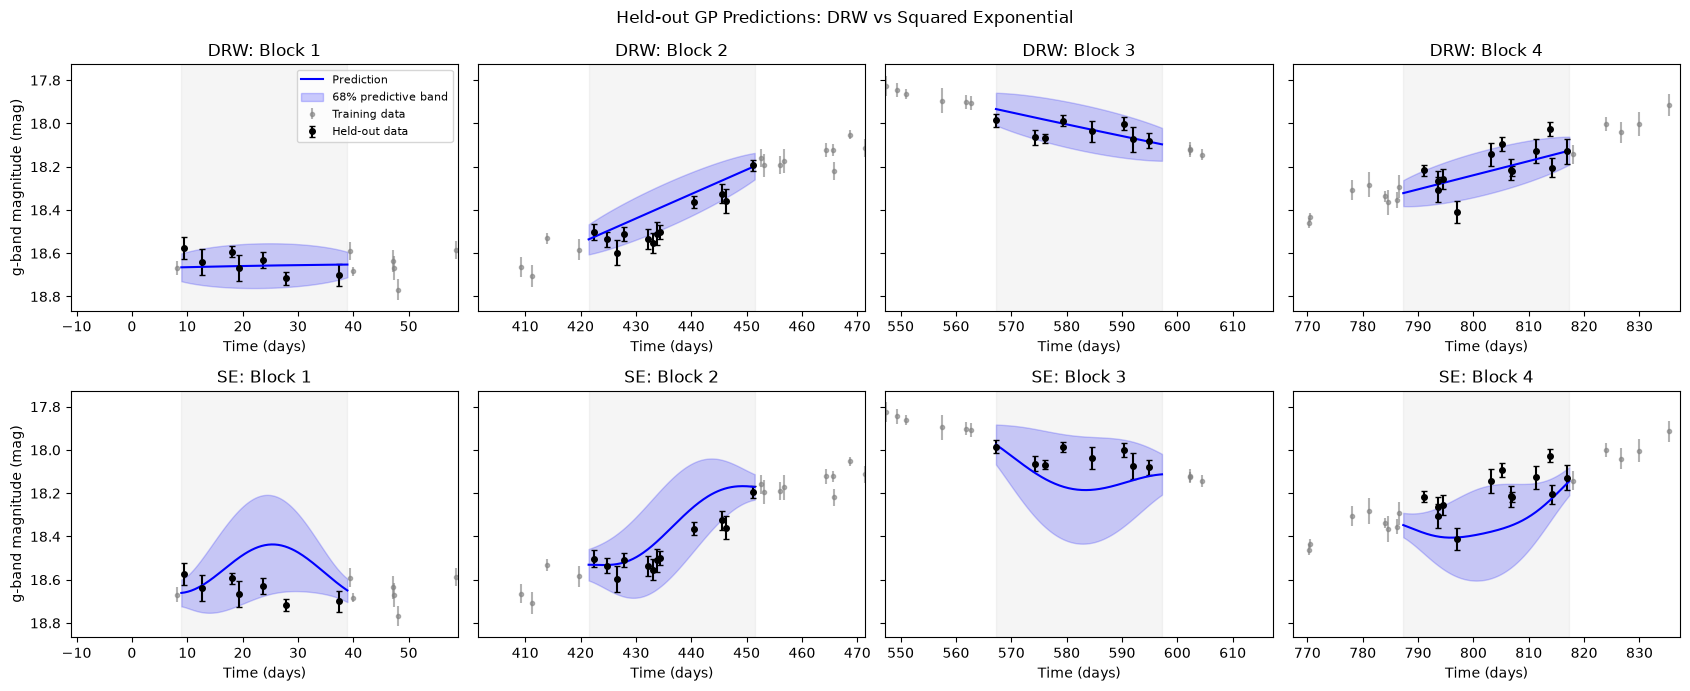

In [35]:
#5.
rng = np.random.default_rng(457)

# Identify observing seasons
ts = np.sort(t)
seasons = np.split(ts, np.where(np.diff(ts) > 60)[0] + 1)
eligible = [(s[0], s[-1]) for s in seasons if np.ptp(s) >= 30]

#Draw random 30 day blocks
for attempt in range(100000):
    blocks = []

    for _ in range(4):
        a, b = eligible[rng.integers(len(eligible))]
        start = rng.uniform(a, b - 30)
        blocks.append((start, start + 30))

    blocks.sort()

    separated = all(blocks[i+1][0] - blocks[i][1] >= 60
                    for i in range(3))

    populated = all(np.sum((t >= a) & (t < b)) >= 2
                    for a, b in blocks)

    if separated and populated:
        break
else:
    raise RuntimeError("Could not find four valid holdout blocks.")

test_mask = np.zeros(len(t), dtype=bool)

for a, b in blocks:
    test_mask |= (t >= a) & (t < b)

train_mask = ~test_mask

t_train, y_train, e_train = t[train_mask], y[train_mask], e[train_mask]
t_test, y_test, e_test = t[test_mask], y[test_mask], e[test_mask]

print("HOLDOUT BLOCKS")
for i, (a, b) in enumerate(blocks):
    n_block = np.sum((t >= a) & (t < b))
    print(f"Block {i+1}: {a:.1f}–{b:.1f} days, {n_block} points")

print(f"\nTraining points = {len(t_train)}")
print(f"Held-out points = {len(t_test)}")

# Kernel covariance function
def kernel_cov(t1, t2, sigma, scale, kernel):
    delta = np.abs(t1[:, None] - t2[None, :])

    if kernel == "DRW":
        return sigma**2 * np.exp(-delta / scale)
    else:
        return sigma**2 * np.exp(-0.5 * (delta / scale)**2)

def train_nll(theta, kernel):
    mu, ln_sigma, ln_scale = theta
    sigma, scale = np.exp(ln_sigma), np.exp(ln_scale)

    C = kernel_cov(t_train, t_train, sigma, scale, kernel)
    C[np.diag_indices_from(C)] += e_train**2

    try:
        cf = cho_factor(C, lower=True, check_finite=False)
        r = y_train - mu
        alpha = cho_solve(cf, r, check_finite=False)

        return (0.5 * r @ alpha
                + np.sum(np.log(np.diag(cf[0])))
                + 0.5 * len(t_train) * np.log(2*np.pi))
    except np.linalg.LinAlgError:
        return np.inf

def gp_predict(theta, kernel, tp, ep):
    mu, ln_sigma, ln_scale = theta
    sigma, scale = np.exp(ln_sigma), np.exp(ln_scale)

    C = kernel_cov(t_train, t_train, sigma, scale, kernel)
    C[np.diag_indices_from(C)] += e_train**2

    K_star = kernel_cov(tp, t_train, sigma, scale, kernel)

    cf = cho_factor(C, lower=True, check_finite=False)
    alpha = cho_solve(cf, y_train - mu, check_finite=False)

    mean = mu + K_star @ alpha

    V = cho_solve(cf, K_star.T, check_finite=False)
    latent_var = sigma**2 - np.sum(K_star * V.T, axis=1)

    pred_std = np.sqrt(np.maximum(latent_var, 0) + np.asarray(ep)**2)

    return mean, pred_std

fits = {}
predictions = {}

for kernel, initial in [
    ("DRW", [np.mean(y_train), np.log(np.std(y_train)), np.log(150)]),
    ("SE", [np.mean(y_train), np.log(np.std(y_train)), np.log(30)])
]:

    fit = minimize(
        lambda th: train_nll(th, kernel),
        np.asarray(initial),
        method="L-BFGS-B",
        bounds=[(None, None), (np.log(0.01), np.log(3)),
                (np.log(10), np.log(4000))]
    )

    fits[kernel] = fit

    if not fit.success:
        print(f"Warning: {kernel} optimizer: {fit.message}")

    pred_mean, pred_std = gp_predict(
        fit.x, kernel, t_test, e_test
    )

    predictions[kernel] = (pred_mean, pred_std)

    inside = np.abs(y_test - pred_mean) <= pred_std
    coverage = np.mean(inside)

    train_mean = np.mean(y_train)

    r2 = 1 - (
        np.sum((y_test - pred_mean)**2) /
        np.sum((y_test - train_mean)**2)
    )

    print(f"\n{kernel} KERNEL")
    print(f"Number held out = {len(t_test)}")
    print(f"Inside 68% band = {np.sum(inside)}/{len(t_test)}")
    print(f"Coverage fraction = {coverage:.3f} ({coverage:.1%})")
    print(f"R² = {r2:.4f}")
    print(f"Training maximum lnL = {-fit.fun:.3f}")

fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey=True)

for row, kernel in enumerate(["DRW", "SE"]):
    for col, (a, b) in enumerate(blocks):
        ax = axes[row, col]

        tg = np.linspace(a, b, 150)

        block_test = (t_test >= a) & (t_test < b)
        e_typical = np.median(e_test[block_test])

        mg, sg = gp_predict(fits[kernel].x, kernel, tg, e_typical)

        nearby = train_mask & (t >= a-20) & (t <= b+20)

        ax.errorbar(t[nearby], y[nearby], yerr=e[nearby],
                    fmt='.', color='gray', alpha=0.6,
                    label='Training data')

        ax.errorbar(t_test[block_test], y_test[block_test],
                    yerr=e_test[block_test], fmt='o',
                    color='black', ms=4, capsize=2,
                    label='Held-out data')

        ax.plot(tg, mg, color='blue', label='Prediction')

        ax.fill_between(tg, mg-sg, mg+sg,
                        color='blue', alpha=0.2,
                        label='68% predictive band')

        ax.axvspan(a, b, color='gray', alpha=0.08)

        ax.set_xlim(a-20, b+20)
        ax.set_title(f"{kernel}: Block {col+1}")
        ax.set_xlabel('Time (days)')

    axes[row, 0].set_ylabel('g-band magnitude (mag)')

axes[0, 0].legend(fontsize=8)
plt.suptitle('Held-out GP Predictions: DRW vs Squared Exponential')
axes[0, 0].invert_yaxis()
plt.tight_layout()
plt.show()

I held out four non-overlapping 30 day blocks containing 40 observations total and refitted both kernels using the remaining 233 observations.

The DRW kernel achieved 72.5% coverage  and $\R^2=0.9117$, while the SE kernel achieved 70.0% coverage and $\R^2=0.7222$. Both coverage fractions are reasonably close to the expected 68%, suggesting that their predictive uncertainty bands are approximately calibrated.

The DRW has a substantially higher $R^2$ and follows the held out observations more closely. The SE model produces larger deviations, suggesting that it does not capture the quasar's irregular variability as well as the DRW.

**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

$\sigma = $ 0.5039 (+0.4588 / −0.1989) mag, $\tau = $ \(\tau = 529.84\) (+1492.62 / −340.28) d, $T/\tau = $ 1.809; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 63.180; 29 of 40 held-out points are inside the 68% band.


## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


1.

I will claim evidence for a periodic signal only if the empirical p-value is below 0.01. This means that fewer than 1% of simulated DRW-only light curves should produce a Lomb Scargle peak at least as strong as the observed maximum. I chose this threshold because quasars naturally exhibit correlated variability that can produce strong periodogram peaks even without a real periodic signal. A strict threshold reduces the chance of falsely identifying random variability as periodicity.


Number of DRW simulations = 2000
Observed maximum LS power = 0.4126
Simulations exceeding observed peak = 780/2000
Empirical p-value = 0.39000
Astropy white-noise FAP = 3.3158e-29
Empirical p >= 0.01: does not pass periodicity threshold.


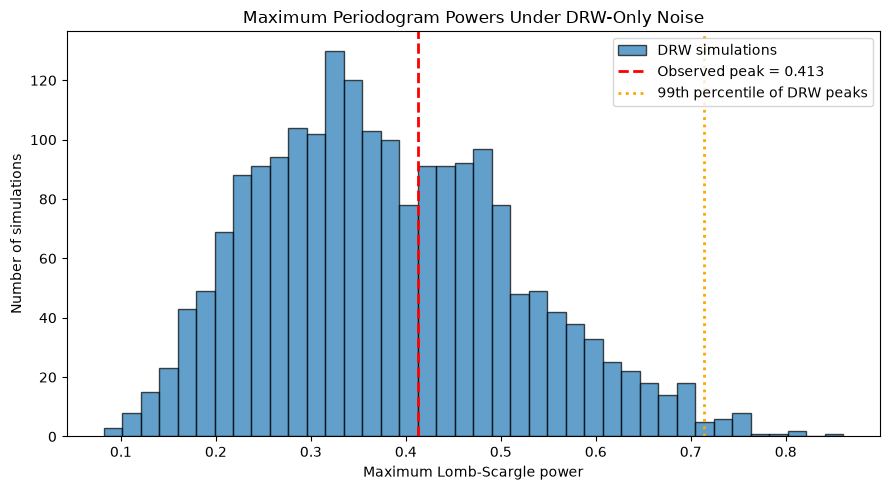

In [36]:
# Part 3: your work here
#2.

rng = np.random.default_rng(457)
n_sim = 2000

mu_sim = mle[0]
sigma_sim = np.exp(mle[1])
tau_sim = np.exp(mle[2])

K = sigma_sim**2 * np.exp(-dt / tau_sim)

L = np.linalg.cholesky(K + 1e-12 * np.eye(len(t)))

max_powers = np.empty(n_sim)

for i in range(n_sim):
    z = rng.normal(size=len(t))
    noise = rng.normal(scale=e)

    y_sim = mu_sim + L @ z + noise

    ls_sim = LombScargle(t, y_sim, dy=e)
    sim_power = ls_sim.power(freq)

    max_powers[i] = np.max(sim_power)

n_exceed = np.sum(max_powers >= peak_power)
p_emp = n_exceed / n_sim

print(f"Number of DRW simulations = {n_sim}")
print(f"Observed maximum LS power = {peak_power:.4f}")
print(f"Simulations exceeding observed peak = {n_exceed}/{n_sim}")
print(f"Empirical p-value = {p_emp:.5f}")
print(f"Astropy white-noise FAP = {fap:.4e}")

if p_emp < 0.01:
    print("Empirical p < 0.01: passes periodicity threshold.")
else:
    print("Empirical p >= 0.01: does not pass periodicity threshold.")

plt.figure(figsize=(9, 5))

plt.hist(max_powers, bins=40, alpha=0.7,
         edgecolor='black', label='DRW simulations')

plt.axvline(peak_power, color='red', linestyle='--',
            linewidth=2, label=f'Observed peak = {peak_power:.3f}')

plt.axvline(np.percentile(max_powers, 99),
            color='orange', linestyle=':',
            linewidth=2, label='99th percentile of DRW peaks')

plt.xlabel('Maximum Lomb-Scargle power')
plt.ylabel('Number of simulations')
plt.title('Maximum Periodogram Powers Under DRW-Only Noise')
plt.legend()
plt.tight_layout()
plt.show()

Out of 2000 simulated DRW-only light curves, 780 produced a maximum Lomb Scargle power at least as large as the observed peak of 0.4126. This gives a p-value of 0.390, well above my preselected threshold of $0.01$. Therefore, I do not find significant evidence for periodicity.

This is much larger than astropy's false-alarm probability of $3.32\times10^{-29}$ because astropy assumes white noise, while quasars exhibit correlated DRW variability. Correlated noise can naturally produce strong periodogram peaks without any true periodic signal, making the white noise FAP overly optimistic.

SINUSOID + DRW FIT
Best period = 191.87 days
Best amplitude = 0.1902 mag
Best phase = 1.000 rad
Maximum delta chi² = 14.201

EMPIRICAL SIGNIFICANCE
Simulations = 2000
Exceedances = 183/2000
Empirical p-value = 0.0915

SENSITIVITY TO TAU
MLE       : tau = 160.92 d, best P = 191.87 d, delta chi² = 14.201, p = 0.0915
Lower 68% : tau = 189.56 d, best P = 191.87 d, delta chi² = 16.303, p = 0.0375
Upper 68% : tau = 2022.46 d, best P = 191.87 d, delta chi² = 143.567, p = 0.0000

PERIODICITY VERDICT
Does not pass the preselected p < 0.01 threshold.


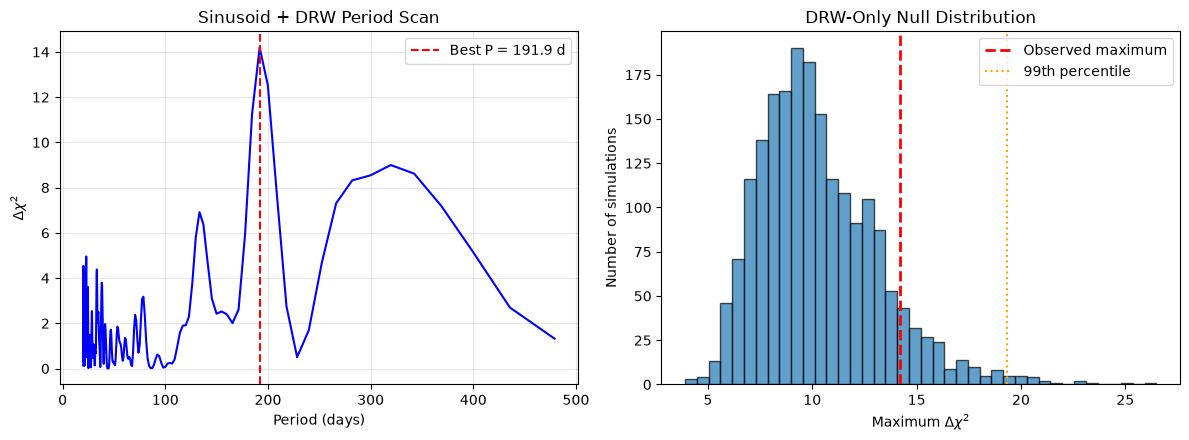

In [37]:
# 3.
from scipy.linalg import solve_triangular

rng = np.random.default_rng(457)
n_sim = 2000
n = len(t)
n_freq = len(freq)

sigma_fixed = np.exp(mle[1])
tau_mle = np.exp(mle[2])

z_drw = rng.normal(size=(n, n_sim))
z_noise = rng.normal(size=(n, n_sim))

omega_t = 2 * np.pi * t[:, None] * freq[None, :]
trig = np.column_stack((np.cos(omega_t), np.sin(omega_t)))
ones = np.ones(n)


def sinusoid_drw_test(tau_value):

    K = sigma_fixed**2 * np.exp(-dt / tau_value)
    C = K + np.diag(e**2)

    L = np.linalg.cholesky(C)
    L_drw = np.linalg.cholesky(K + 1e-12 * np.eye(n))

    yw = solve_triangular(L, y, lower=True)
    q = solve_triangular(L, ones, lower=True)
    W = solve_triangular(L, trig, lower=True)

    W -= np.outer(q, (q @ W) / (q @ q))

    U = W[:, :n_freq]
    V = W[:, n_freq:]

    g11 = np.sum(U**2, axis=0)
    g22 = np.sum(V**2, axis=0)
    g12 = np.sum(U * V, axis=0)

    det = g11*g22 - g12**2

    b1 = U.T @ yw
    b2 = V.T @ yw

    delta_chi2 = (
        g22*b1**2 - 2*g12*b1*b2 + g11*b2**2
    ) / det

    best_idx = np.argmax(delta_chi2)
    best_period = 1 / freq[best_idx]
    best_delta = delta_chi2[best_idx]

    X = np.column_stack((
        ones,
        np.cos(2*np.pi*t/best_period),
        np.sin(2*np.pi*t/best_period)
    ))

    Xw = solve_triangular(L, X, lower=True)
    beta = np.linalg.solve(Xw.T @ Xw, Xw.T @ yw)

    amplitude = np.hypot(beta[1], beta[2])
    phase = np.arctan2(beta[1], beta[2])

    y_sims = (
        mle[0] + L_drw @ z_drw + e[:, None] * z_noise
    )

    yw_sims = solve_triangular(L, y_sims, lower=True)

    bs1 = U.T @ yw_sims
    bs2 = V.T @ yw_sims

    delta_sims = (
        g22[:, None]*bs1**2
        - 2*g12[:, None]*bs1*bs2
        + g11[:, None]*bs2**2
    ) / det[:, None]

    max_delta_sims = np.max(delta_sims, axis=0)

    exceed = np.sum(max_delta_sims >= best_delta)
    p_value = exceed / n_sim

    return {
        "tau": tau_value,
        "period": best_period,
        "delta": best_delta,
        "amplitude": amplitude,
        "phase": phase,
        "p": p_value,
        "exceed": exceed,
        "curve": delta_chi2,
        "sim_max": max_delta_sims
    }


test_mle = sinusoid_drw_test(tau_mle)
test_low = sinusoid_drw_test(t16)
test_high = sinusoid_drw_test(t84)

print("SINUSOID + DRW FIT")
print(f"Best period = {test_mle['period']:.2f} days")
print(f"Best amplitude = {test_mle['amplitude']:.4f} mag")
print(f"Best phase = {test_mle['phase']:.3f} rad")
print(f"Maximum delta chi² = {test_mle['delta']:.3f}")

print("\nEMPIRICAL SIGNIFICANCE")
print(f"Simulations = {n_sim}")
print(f"Exceedances = {test_mle['exceed']}/{n_sim}")
print(f"Empirical p-value = {test_mle['p']:.4f}")

print("\nSENSITIVITY TO TAU")
for label, result in [
    ("MLE", test_mle),
    ("Lower 68%", test_low),
    ("Upper 68%", test_high)
]:
    print(
        f"{label:10s}: tau = {result['tau']:.2f} d, "
        f"best P = {result['period']:.2f} d, "
        f"delta chi² = {result['delta']:.3f}, "
        f"p = {result['p']:.4f}"
    )

print("\nPERIODICITY VERDICT")
if test_mle["p"] < 0.01:
    print("Passes the preselected p < 0.01 threshold.")
else:
    print("Does not pass the preselected p < 0.01 threshold.")


fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(1/freq, test_mle["curve"], color="blue")
ax[0].axvline(test_mle["period"], color="red",
              ls="--", label=f"Best P = {test_mle['period']:.1f} d")
ax[0].set_xlabel("Period (days)")
ax[0].set_ylabel(r"$\Delta\chi^2$")
ax[0].set_title("Sinusoid + DRW Period Scan")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].hist(test_mle["sim_max"], bins=40,
           alpha=0.7, edgecolor="black")
ax[1].axvline(test_mle["delta"], color="red", ls="--",
              linewidth=2, label="Observed maximum")
ax[1].axvline(np.percentile(test_mle["sim_max"], 99),
              color="orange", ls=":",
              label="99th percentile")
ax[1].set_xlabel(r"Maximum $\Delta\chi^2$")
ax[1].set_ylabel("Number of simulations")
ax[1].set_title("DRW-Only Null Distribution")
ax[1].legend()

plt.tight_layout()
plt.show()


Using the maximum-likelihood DRW parameters, the best fitting sinusoid has a period of 191.87 days and an amplitude of 0.1902 mag, with a maximum improvement of $\Delta\chi^2=14.201$. Of 2000 DRW only simulations, 183 produced a larger maximum improvement, giving a p-value of 0.0915. This is above my preselected threshold of 0.01, so I do not find significant evidence for periodicity.

The result is sensitive to the assumed damping time. At the lower 68% limit of $\tau=189.56$ days, the p-value decreases to 0.0375, while at the upper limit of $\tau=2022.46$ days, none of the 2000 simulations exceed the observed statistic. However, these tests hold $\sigma$ fixed even though $\sigma$ and $\tau$ are correlated, so the result at large $\tau$ might not be accurate.

The best-fit period also differs from the original Lomb Scargle peak near 300 days because this fit explicitly accounts for correlated DRW noise. Overall, the periodicity claim is not significant at the maximum-likelihood parameters and is not robust to uncertainty in the noise model.

**ANSWER (the decision rule first, then the verdict):**


By my threshold of $p<0.01$, there is no significant evidence for a periodic signal. The empirical p-value from the Lomb Scargle test was 0.390, while the sinusoid + DRW fit gave $p=0.0915$, both above my threshold. Although the best fit sinusoid has a period of 191.87 days and an amplitude of 0.1902 mag, the improvement is not significant compared with DRW-only simulations. I would need a stronger periodic signal that passes the $p<0.01$ threshold under realistic DRW noise, ideally supported by a longer observing baseline showing repeated cycles.

The team should not announce a binary black hole candidate based on this evidence because the apparent periodicity can reasonably be explained by quasar variability.


## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


**REFEREE REPORT:**


1. Incorrect significance test for periodicity

Error: The AI uses astropy's Lomb Scargle FAP to claim a highly significant period. However, this assumes white noise, while quasars have correlated DRW variability. This can make random fluctuations appear more significant than they really are.

Correct treatment: Simulate DRW-only light curves using the actual observing times and measurement errors. Compare the highest periodogram peak from each simulation to the observed peak to calculate an empirical p-value.

Effect on results: The AI reports a false-alarm probability of about $3.32\times10^{-29}$, suggesting a very strong detection. However, my 2000 DRW simulations gave $p=0.390$, meaning 39% of simulated light curves produced an equally strong or stronger peak. The periodicity is therefore not significant under the DRW model.

2. Using the wrong Gaussian process kernel

Error: The AI assumes quasar variability is smooth and uses a squared-exponential kernel without comparing it to the DRW kernel. The SE kernel assumes smoother variations than the irregular brightness changes typically seen in quasars.

Correct treatment: Fit both the DRW and SE kernels and compare their maximum log-likelihoods using the same parameter bounds. Use the better fitting kernel to model the quasar's variability.

Effect on results: The DRW gives a maximum $\ln L=348.179$, compared with 284.999 for the squared-exponential kernel, a difference of 63.180. Repeating the AI's unconstrained fit gives $\ln L=285.009$, so the difference remains 63.170. This shows that changing the parameter bounds barely affects the result. The DRW fits better, suggesting the light curve is less smooth than the AI assumed.

3. Incorrect cross-validation method

Error: The AI fits its GP parameters using the entire dataset before cross validation, so the held-out points already influenced the model. It also randomly holds out individual observations, leaving nearby correlated observations in the training set. This can make the predictions look better than they would across actual gaps.

Correct treatment: Hold out four separate 30-day blocks within observing seasons, with at least 60 days between them. Refit the GP parameters using only the training data, then predict the held-out points and calculate the 68% coverage and $R^2$ against the training mean.

Effect on results: The original random cross-validation gives $R^2=0.9666$ and 60.8% coverage. Refitting the parameters on training data only gives $R^2=0.9652$ and 56.4% coverage. Therefore, data leakage has only a small effect on $R^2$ for this dataset.

Using 30-day holdout blocks gives $R^2=0.7222$ and 70.0% coverage for the squared-exponential kernel. The much lower $R^2$ shows that predicting across longer gaps is harder than predicting randomly held-out individual observations. Since the test sets differ, this is not an exact measure of the effect of random sampling alone, but it shows why blocked validation is more useful for this time series.

The blocked coverage is also closer to the expected 68%, suggesting more reasonable predictive uncertainties.

In [38]:
# Part 5: your work here
#1. 

# Error 1: White-noise FAP vs DRW significance

print(f"Astropy white-noise FAP = {fap:.3e}")
print(f"Empirical DRW p-value = {p_emp:.4f}")
print(f"DRW simulations exceeding peak = "
      f"{np.sum(max_powers >= peak_power)}/{len(max_powers)}")

print(f"\nSignificant under white noise? {fap < 0.01}")
print(f"Significant under DRW noise? {p_emp < 0.01}")


Astropy white-noise FAP = 3.316e-29
Empirical DRW p-value = 0.3900
DRW simulations exceeding peak = 780/2000

Significant under white noise? True
Significant under DRW noise? False


In [39]:
#2.


# Error 2: DRW vs squared-exponential kernel

# Reproduce the AI's unconstrained SE fit
ai_se = minimize(
    lambda p: -log_likelihood_se(p),
    [y.mean(), np.log(y.std()), np.log(30)],
    method="Nelder-Mead",
    options={"maxiter": 1500}
)

print(f"DRW maximum lnL = {lnL_drw:.3f}")
print(f"SE maximum lnL (same bounds) = {lnL_se:.3f}")
print(f"Difference = {lnL_drw - lnL_se:.3f}")

print(f"\nAI unconstrained SE lnL = {-ai_se.fun:.3f}")
print(f"DRW - AI SE difference = {lnL_drw + ai_se.fun:.3f}")
print(f"AI SE length scale = {np.exp(ai_se.x[2]):.2f} days")


DRW maximum lnL = 348.179
SE maximum lnL (same bounds) = 284.999
Difference = 63.180

AI unconstrained SE lnL = 285.009
DRW - AI SE difference = 63.170
AI SE length scale = 9.92 days


In [40]:
#3. 

# Error 3: Cross-validation comparison

rng_cv = np.random.default_rng(1)
folds_cv = rng_cv.permutation(len(t)) % 5

# Likelihood for an arbitrary training subset
def cv_nll(p, tr):
    mu, ls, ll = p
    C = kernel_cov(t[tr], t[tr], np.exp(ls), np.exp(ll), "SE")
    C += np.diag(e[tr]**2)

    cf = cho_factor(C, lower=True)
    r = y[tr] - mu

    return (0.5 * r @ cho_solve(cf, r)
            + np.log(np.diag(cf[0])).sum()
            + 0.5 * tr.sum() * np.log(2*np.pi))


# Predict held-out points
def cv_predict(p, tr, te):
    mu, ls, ll = p
    sig, ell = np.exp(ls), np.exp(ll)

    C = kernel_cov(t[tr], t[tr], sig, ell, "SE")
    C += np.diag(e[tr]**2)

    Ks = kernel_cov(t[te], t[tr], sig, ell, "SE")
    cf = cho_factor(C, lower=True)

    mean = mu + Ks @ cho_solve(cf, y[tr] - mu)
    var = sig**2 - np.sum(Ks * cho_solve(cf, Ks.T).T, axis=1)

    return mean, np.sqrt(np.maximum(var, 0) + e[te]**2)


pred_leak = np.empty(len(t))
sd_leak = np.empty(len(t))
pred_clean = np.empty(len(t))
sd_clean = np.empty(len(t))
baseline = np.empty(len(t))

for k in range(5):
    te = folds_cv == k
    tr = ~te

    # AI method: parameters fitted on all data
    pred_leak[te], sd_leak[te] = cv_predict(best_se.x, tr, te)

    # Corrected: refit using training data only
    fit_cv = minimize(
        lambda p: cv_nll(p, tr),
        [y[tr].mean(), np.log(y[tr].std()), np.log(30)],
        method="L-BFGS-B", bounds=bounds
    )

    pred_clean[te], sd_clean[te] = cv_predict(fit_cv.x, tr, te)
    baseline[te] = y[tr].mean()


def cv_scores(actual, pred, std, base):
    coverage = np.mean(np.abs(actual - pred) <= std)
    r2 = 1 - np.sum((actual - pred)**2) / np.sum((actual - base)**2)
    return coverage, r2


print("SE KERNEL CROSS-VALIDATION")

for name, pred, sd in [
    ("Random CV with leakage", pred_leak, sd_leak),
    ("Random CV, refitted", pred_clean, sd_clean),
    ("30-day blocked CV", *predictions["SE"])
]:
    if name == "30-day blocked CV":
        coverage, r2 = cv_scores(y_test, pred, sd, y_train.mean())
    else:
        coverage, r2 = cv_scores(y, pred, sd, baseline)

    print(f"{name}: coverage = {coverage:.1%}, R² = {r2:.4f}")


SE KERNEL CROSS-VALIDATION
Random CV with leakage: coverage = 60.8%, R² = 0.9666
Random CV, refitted: coverage = 56.4%, R² = 0.9652
30-day blocked CV: coverage = 70.0%, R² = 0.7222


## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [41]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

FileNotFoundError: data/live_objects.csv not found.

Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


**ANSWER (the criterion first, then the result):**

*your answer goes here*

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**
ChatGPT

- Writing print statements and plotting code

- Writing tests, and making functions

- Used ai to help code the tests

- Helping write functions for the GP likelihood, optimization, and simulations.

- Implementing emcee sampling and checking convergence.

- Check my results and help identify anything that needs further testing or explanation.

ChatGPT initially misinterpreted the annual sampling peak as a Lomb Scargle peak, which I caught by checking the actual plot. It also initially treated the cross validation problems together, but further testing showed that data leakage had a small effect while random holdouts made a much larger difference. 
I checked the code outputs, plots, convergence diagnostics, and simulation results.

**REFLECTION:**

Without checking the AI's output, I could have submitted incorrect code, misleading plots, or conclusions that were not supported by my results.

**VERIFICATION PLAN:**

For Part 2, I checked that three starting values gave the same maximum likelihood. I also checked MCMC convergence using autocorrelation times, with chain-length ratios of 55.8 and 59.5. Different maxima or insufficient chain lengths would suggest unreliable results.

I generated synthetic DRW data with known $\sigma=0.28$ mag and $\tau=160$ days. Neither true value fell within the fitted 68% intervals. This could happen by chance, but repeated tests are needed to check whether the intervals are reliable.

For Part 3, the DRW-only simulation gave no significant detection ($p=0.527$). With an injected 190-day sinusoid, the fit recovered 191.9 days, with 0 out of 1000 null simulations exceeding the observed statistic. A false detection or failure to recover the injected signal would be concerning.

These were only two synthetic light curves, with 1000 null simulations used for each significance test. I would repeat the recovery test with at least 1000 independent light curves to check whether the 68% intervals contain the true values about 68% of the time, and ideally use 10,000 noise-only tests to measure the 1% false-positive rate.

In [42]:
rng = np.random.default_rng(457)
np.random.seed(457)

mu_true = np.mean(y)
sigma_true, tau_true = 0.28, 160.0
P_true, A_true = 190.0, 0.65

n = len(t)
n_null = 1000

K_true = sigma_true**2 * np.exp(-dt / tau_true)
L_true = np.linalg.cholesky(K_true + 1e-12*np.eye(n))

y_base = mu_true + L_true @ rng.normal(size=n) + rng.normal(scale=e)
y_injected = y_base + A_true * np.sin(2*np.pi*t/P_true + 0.8)

cases = {"DRW only": y_base, "DRW + sinusoid": y_injected}


def check_loglike(theta, yy):
    mu, ls, lt = theta
    if not (np.log(0.01) < ls < np.log(3) and
            np.log(10) < lt < np.log(4000)):
        return -np.inf

    C = np.exp(2*ls) * np.exp(-dt / np.exp(lt))
    C[np.diag_indices(n)] += e**2

    cf = cho_factor(C, lower=True, check_finite=False)
    r = yy - mu

    return -0.5 * (r @ cho_solve(cf, r, check_finite=False)
                   + 2*np.log(np.diag(cf[0])).sum()
                   + n*np.log(2*np.pi))


def check_periods(yy, theta):
    mu, ls, lt = theta
    sig, tau = np.exp(ls), np.exp(lt)

    K = sig**2 * np.exp(-dt/tau)
    C = K + np.diag(e**2)
    L = np.linalg.cholesky(C)

    obs_ls = LombScargle(t, yy, dy=e).power(freq).max()

    q = solve_triangular(L, np.ones(n), lower=True)
    yw = solve_triangular(L, yy, lower=True)

    wt = 2*np.pi*t[:, None]*freq[None, :]
    W = solve_triangular(
        L, np.column_stack((np.cos(wt), np.sin(wt))), lower=True
    )
    W -= np.outer(q, (q @ W)/(q @ q))

    nf = len(freq)
    U, V = W[:, :nf], W[:, nf:]

    g11 = np.sum(U**2, axis=0)
    g22 = np.sum(V**2, axis=0)
    g12 = np.sum(U*V, axis=0)
    det = g11*g22 - g12**2

    b1, b2 = U.T @ yw, V.T @ yw
    delta = (g22*b1**2 - 2*g12*b1*b2 + g11*b2**2)/det

    idx = np.argmax(delta)
    obs_delta = delta[idx]
    best_period = 1/freq[idx]

    Lk = np.linalg.cholesky(K + 1e-12*np.eye(n))
    ysims = (mu + Lk @ rng.normal(size=(n, n_null))
             + e[:, None]*rng.normal(size=(n, n_null)))

    ls_max = np.array([
        LombScargle(t, ysims[:, j], dy=e).power(freq).max()
        for j in range(n_null)
    ])

    sw = solve_triangular(L, ysims, lower=True)
    c1, c2 = U.T @ sw, V.T @ sw
    sim_delta = (g22[:, None]*c1**2
                 - 2*g12[:, None]*c1*c2
                 + g11[:, None]*c2**2)/det[:, None]

    return (best_period, obs_delta,
            np.mean(ls_max >= obs_ls),
            np.mean(sim_delta.max(axis=0) >= obs_delta))


for name, yy in cases.items():

    starts_check = [
        [yy.mean(), np.log(s), np.log(tau)]
        for s, tau in [(0.15, 40), (0.3, 200), (0.6, 800)]
    ]

    fits_check = [
        minimize(lambda p: -check_loglike(p, yy), x0,
                 method="L-BFGS-B", bounds=bounds)
        for x0 in starts_check
    ]

    fit = min(fits_check, key=lambda r: r.fun)

    pos = fit.x + rng.normal(
        scale=[0.02, 0.08, 0.12], size=(24, 3)
    )
    pos[:, 1] = np.clip(pos[:, 1], bounds[1][0]+1e-5, bounds[1][1]-1e-5)
    pos[:, 2] = np.clip(pos[:, 2], bounds[2][0]+1e-5, bounds[2][1]-1e-5)

    sampler_check = emcee.EnsembleSampler(
        24, 3, lambda p: check_loglike(p, yy)
    )
    sampler_check.run_mcmc(pos, 3000, progress=False)

    ac = sampler_check.get_autocorr_time(tol=0)
    samples_check = sampler_check.get_chain(discard=750, flat=True)

    sig_interval = np.percentile(np.exp(samples_check[:, 1]), [16, 50, 84])
    tau_interval = np.percentile(np.exp(samples_check[:, 2]), [16, 50, 84])

    recovered_P, delta, p_ls, p_gls = check_periods(yy, fit.x)

    print(f"\n===== {name.upper()} =====")
    print(f"MLE lnL spread across starts = "
          f"{np.ptp([-r.fun for r in fits_check]):.3f}")
    print(f"MCMC length / max autocorrelation = {3000/max(ac):.1f}")

    print(f"Sigma 68% interval = {sig_interval[0]:.3f} "
          f"to {sig_interval[2]:.3f} (truth {sigma_true})")
    print(f"Contains true sigma? "
          f"{sig_interval[0] <= sigma_true <= sig_interval[2]}")

    print(f"Tau 68% interval = {tau_interval[0]:.1f} "
          f"to {tau_interval[2]:.1f} d (truth {tau_true})")
    print(f"Contains true tau? "
          f"{tau_interval[0] <= tau_true <= tau_interval[2]}")

    print(f"Best sinusoid period = {recovered_P:.1f} d")
    print(f"Maximum delta chi² = {delta:.2f}")
    print(f"LS empirical p = {p_ls:.4f}")
    print(f"Sinusoid + DRW empirical p = {p_gls:.4f}")
    print(f"Detection by p < 0.01 rule? {p_gls < 0.01}")

    if name == "DRW + sinusoid":
        print(f"Injected period = {P_true:.1f} d")
        print(f"Period recovered within 10%? "
              f"{abs(recovered_P-P_true)/P_true < 0.10}")



===== DRW ONLY =====
MLE lnL spread across starts = 0.000
MCMC length / max autocorrelation = 55.8
Sigma 68% interval = 0.372 to 1.006 (truth 0.28)
Contains true sigma? False
Tau 68% interval = 318.0 to 2365.1 d (truth 160.0)
Contains true tau? False
Best sinusoid period = 48.5 d
Maximum delta chi² = 9.89
LS empirical p = 0.2560
Sinusoid + DRW empirical p = 0.5270
Detection by p < 0.01 rule? False

===== DRW + SINUSOID =====
MLE lnL spread across starts = 0.000
MCMC length / max autocorrelation = 59.5
Sigma 68% interval = 0.599 to 1.658 (truth 0.28)
Contains true sigma? False
Tau 68% interval = 322.3 to 2461.9 d (truth 160.0)
Contains true tau? False
Best sinusoid period = 191.9 d
Maximum delta chi² = 78.61
LS empirical p = 0.0880
Sinusoid + DRW empirical p = 0.0000
Detection by p < 0.01 rule? True
Injected period = 190.0 d
Period recovered within 10%? True
